# 05 RF tier (R): scikit-rf channel model

Each tap path is a scikit-rf two-port cascade
$$\text{coupler}\ \star\ \text{mismatch junction}(\Gamma)\ \star\ \mathrm{Coaxial.line}(k\,d\,T_s\,v_p)\ \star\ \text{mismatch junction}(\Gamma)\ \star\ \text{Wilkinson branch}(1/\sqrt N)$$
and its $S_{21}(f)$ becomes a frequency response $H_{o,i,k}(f)$ (delay-trimmed to the nominal $kdT_s$ at 50 MHz). IFFT gives impulse responses, a symbol-rate FIR per layer is applied with FFT convolution to all examples, then the amplifier (tanh), stage noise and a 10-bit ADC. *Channel level only: no EM, layout or connector effects; the amplifier is memoryless.*

**Per-stage SNR convention (important).** R's `snr_db` is the SNR at **each amplifier input**: with reference power $P_{ref,l}$ of the ideal pre-activation of layer $l$ and noise figure NF,
$$\sigma_l^2=P_{ref,l}\;10^{(\mathrm{NF}-\mathrm{SNR})/10},$$
three independent noise sources (one per layer). V, E and C instead add AWGN at the **input** only. So the `snr_db` axes of R and V/E are not the same quantity; the demonstration below makes the difference explicit.

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")
import skrf
from dlnn.tiers import rf, virtual
from dlnn import cascade, sweeps
from dlnn.tiers.common import softmax, mean_kl
model = run.model
x_all, y_all = run.x_test, run.labels
N = nb.n_subset(500)
xs, ys = x_all[:N], y_all[:N]
# the run's own operating point for R: defaults, plus the cascade hook (SPICE line loss + diff-pair scales) if the run used --cascade
cfg_run = {}
if run.cascade:
    ex_ = cascade.load_extracted(run.dir / "params" / "circuit_extracted.json")
    cfg_run = cascade.apply_to_rf_cfg({}, ex_); cfg_run["amp_offset_rel"] = float(ex_["amp"]["offset_rel"])
rc = rf.resolve_cfg(cfg_run)
print("scikit-rf", skrf.__version__, "| R operating point of this run: loss", round(rc["loss_db_per_us"], 2), "dB/us, isolation", rc["isolation_db"], "dB, tap err", rc["tap_amp_err_db"], "dB /", rc["tap_phase_err_deg"], "deg, Gamma", rc["gamma_mismatch"],
      "crosstalk", rc["crosstalk_db"], "dB, stage SNR", rc["snr_db"], "dB, NF", rc["nf_db"], "dB, ADC", rc["adc_bits"], "bit")
print("subset for live computations: first", N, "test examples (not class/SNR balanced); the stored sweeps below use all 4000")

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000
scikit-rf 2.2.0 | R operating point of this run: loss 32.0 dB/us, isolation 30.0 dB, tap err 0.5 dB / 5.0 deg, Gamma 0.05 crosstalk -35.0 dB, stage SNR 30.0 dB, NF 3.0 dB, ADC 10 bit
subset for live computations: first 500 test examples (not class/SNR balanced); the stored sweeps below use all 4000


## A scikit-rf line network, built by hand

Coaxial medium: Dint 0.90 mm, Dout 3.18 mm (sets Z0 = 50 ohm), eps_r 2.293 (v_p = 19.8 cm/ns), sigma 2.44e+07 S/m, tan_delta 0.0002
(sigma and tan_delta were solved so that the matched-line loss at 100 MHz equals the requested dB/us)


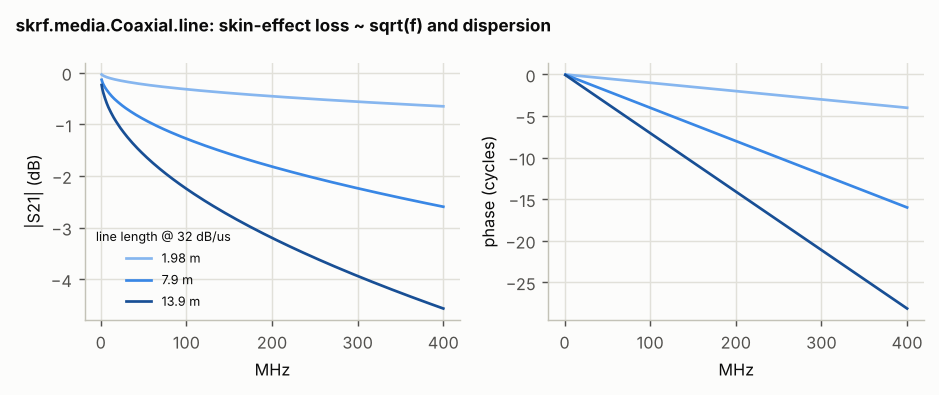

skrf network object of one line: 2-Port Network: '',  1.0-400.0 MHz, 400 pts, z0=[50.+0.j 50.+0.j]


In [2]:
import skrf as rfk
from skrf.media import Coaxial
eps, dint, dout = rf._coax_geometry(rc)
sigma, tand = rf.coax_parameters(rc)
freq = rfk.Frequency(1, 400, 400, "MHz")
med = Coaxial(freq, z0_port=50, Dint=dint, Dout=dout, epsilon_r=eps, tan_delta=tand, sigma=sigma)
print(f"Coaxial medium: Dint {1e3 * dint:.2f} mm, Dout {1e3 * dout:.2f} mm (sets Z0 = 50 ohm), eps_r {eps:.3f} (v_p = {rc['vp_cm_per_ns']} cm/ns), sigma {sigma:.3g} S/m, tan_delta {tand:.2g}")
print("(sigma and tan_delta were solved so that the matched-line loss at 100 MHz equals the requested dB/us)")
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
for L, c in zip((1.98, 7.9, 13.9), ("#86b6ef", "#3987e5", "#184f95")):
    ln = med.line(L, unit="m")
    s21 = ln.s[:, 1, 0]
    axs[0].plot(freq.f / 1e6, 20 * np.log10(np.abs(s21)), color=c, label=f"{L} m"); axs[1].plot(freq.f / 1e6, np.unwrap(np.angle(s21)) / (2 * np.pi), color=c)
axs[0].set_xlabel("MHz"); axs[0].set_ylabel("|S21| (dB)"); axs[0].legend(fontsize=7, title=f"line length @ {rc['loss_db_per_us']:.0f} dB/us", title_fontsize=7)
axs[1].set_xlabel("MHz"); axs[1].set_ylabel("phase (cycles)")
fig.suptitle("skrf.media.Coaxial.line: skin-effect loss ~ sqrt(f) and dispersion", x=0.01, ha="left", fontsize=9.5, fontweight="bold"); fig.tight_layout(); nb.show_fig(fig)
print("skrf network object of one line:", ln)

## One complete tap path (coupler, mismatch, line, mismatch, Wilkinson) and its dependence on loss

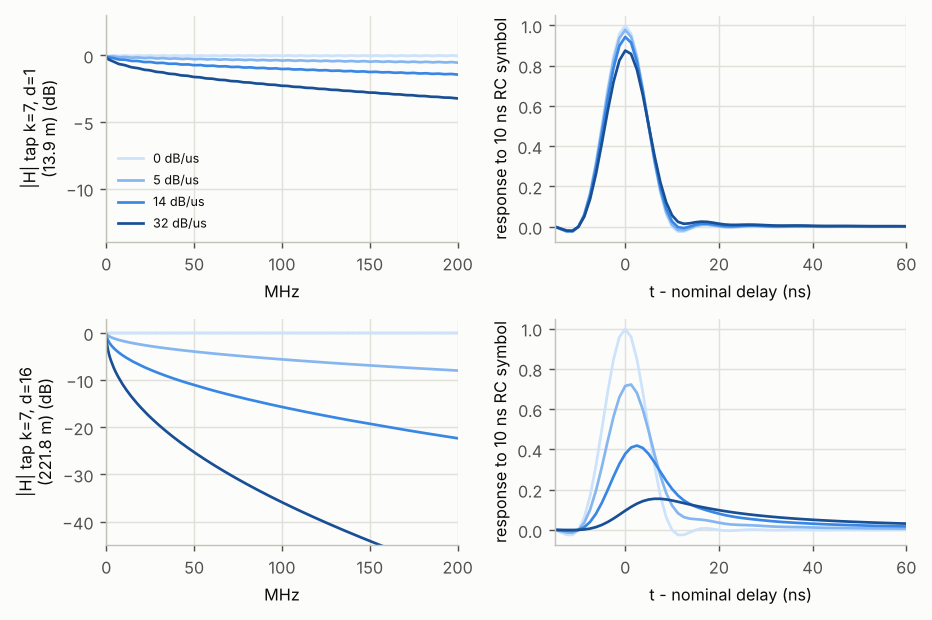

*(top: the longest layer-1 tap, 13.9 m; bottom: the longest layer-3 tap, 222 m = 1.12 us. Static coupler / combiner gain divided out.)* At 32 dB/us the layer-3 tap loses about **36 dB** and is visibly smeared; without per-tap repeaters this operating point is not buildable. It is not the whole reason C and R fall behind V in the full-set tables: for C the default per-layer gain trim accounts for most of the gap (notebook 04, loss-compensation section).

In [3]:
g = rf.make_grid(rc, 3 * 16 * 7 + 16)
Ts = 10e-9
def rc_spec(f):
    x_ = np.clip(f * Ts, 0, 1); return np.where(f * Ts <= 1.0, 0.5 * Ts * (1 + np.cos(np.pi * x_)), 0.0)
fig, axs = plt.subplots(2, 2, figsize=(7.2, 4.8))
cols = {0.0: "#cde2fb", 5.0: "#86b6ef", 14.0: "#3987e5", 32.0: "#184f95"}
for (kk, dd), axr in zip(((7, 1), (7, 16)), axs):
    for loss, c in cols.items():
        rc_ = dict(rc, loss_db_per_us=loss)
        H, stat = rf.line_response(rc_, g, kk * dd, 16 if dd == 1 else 256)
        Hn = H / stat
        axr[0].plot(g.f[1:] / 1e6, 20 * np.log10(np.abs(Hn[1:]) + 1e-9), color=c, label=f"{loss:g} dB/us")
        yy = np.fft.irfft(Hn * rc_spec(g.f), n=g.N) * g.fs
        tt = np.arange(g.N) * Ts / g.U; tt = np.where(tt > tt[-1] / 2, tt - tt[-1] - tt[1], tt)
        o_ = np.argsort(tt); axr[1].plot(tt[o_] * 1e9, yy[o_], color=c)
    axr[0].set_xlim(0, 200); axr[0].set_ylim(-45 if dd == 16 else -14, 3); axr[0].set_ylabel(f"|H| tap k={kk}, d={dd}\n({kk * dd * 1.98:.1f} m) (dB)"); axr[0].set_xlabel("MHz")
    axr[1].set_xlim(-15, 60); axr[1].set_ylabel("response to 10 ns RC symbol"); axr[1].set_xlabel("t - nominal delay (ns)")
axs[0, 0].legend(fontsize=7)
fig.tight_layout(); nb.show_fig(fig)
nb.md("*(top: the longest layer-1 tap, 13.9 m; bottom: the longest layer-3 tap, 222 m = 1.12 us. Static coupler / combiner gain divided out.)* At 32 dB/us the layer-3 tap loses about **36 dB** and is visibly smeared; without per-tap repeaters this operating point is not buildable. It is not the whole reason C and R fall behind V in the full-set tables: for C the default per-layer gain trim accounts for most of the gap (notebook 04, loss-compensation section).")

## Live parameter sweeps on the subset (compared with the stored 4000-example sweeps)

In [4]:
t0 = time.time()
pref = rf.reference_power(model, xs)
Vclean = virtual.forward(model, xs)["out"]; pV = softmax(Vclean)
def score(out):
    return float((out.argmax(1) == ys).mean()), float((out.argmax(1) == Vclean.argmax(1)).mean()), mean_kl(pV, softmax(out))
plan = {"snr_db": [0.0, 5.0, 10.0, 15.0, 20.0, 30.0], "loss_db_per_us": [0.0, 5.0, 14.0, 32.0], "isolation_db": [15.0, 20.0, 25.0, 30.0, 35.0, 40.0],
        "tap_amp_err_db": [0.0, 0.25, 0.5, 1.0, 2.0], "adc_bits": [4, 5, 6, 7, 8, 9, 10]}
chans, _ = rf.build_channels(model, rc)
live = {}
for axis, vals in plan.items():
    res = []
    for v in vals:
        rcv = dict(rc, **{axis: v})
        ch = chans if axis in ("snr_db", "adc_bits") else rf.build_channels(model, rcv)[0]
        res.append(score(rf.forward_with(model, xs, rcv, ch, pref)["out"]))
    live[axis] = np.array(res)
    print(f"{axis:15s} done ({time.time() - t0:.0f} s)")
print(f"total live sweep time on {N} examples: {time.time() - t0:.0f} s")

snr_db          done (6 s)


loss_db_per_us  done (16 s)


isolation_db    done (19 s)


tap_amp_err_db  done (22 s)


adc_bits        done (25 s)
total live sweep time on 500 examples: 25 s


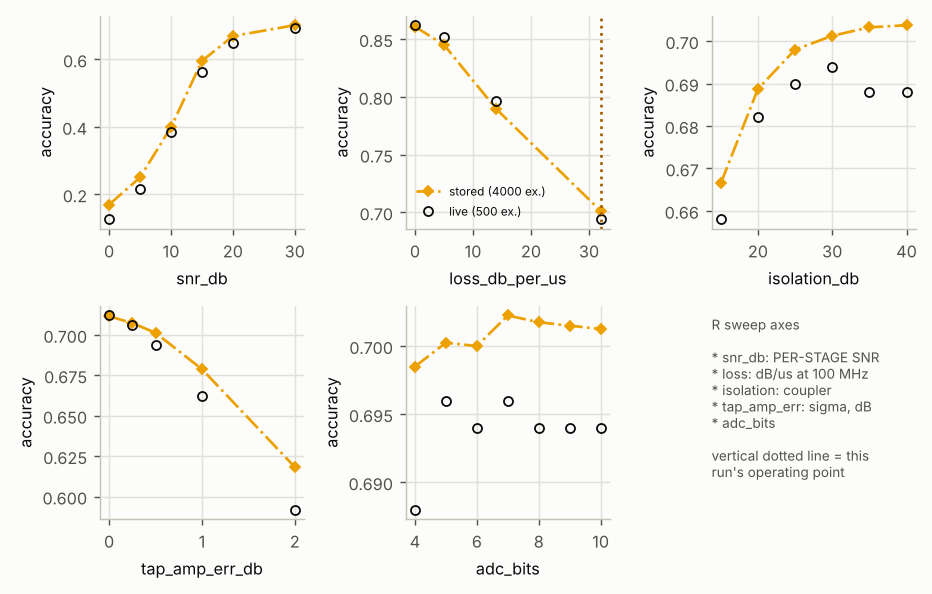

| axis | value | live accuracy | live agreement with V | live mean KL | stored accuracy (4000) |
|---|---|---|---|---|---|
| snr_db | 0 | 0.126 | 0.130 | 3.217 | 0.170 |
| snr_db | 5 | 0.216 | 0.214 | 4.845 | 0.250 |
| snr_db | 10 | 0.384 | 0.370 | 3.265 | 0.399 |
| snr_db | 15 | 0.564 | 0.548 | 1.634 | 0.595 |
| snr_db | 20 | 0.648 | 0.632 | 1.077 | 0.669 |
| snr_db | 30 | 0.694 | 0.682 | 0.837 | 0.701 |
| loss_db_per_us | 0 | 0.862 | 0.968 | 0.012 | 0.861 |
| loss_db_per_us | 5 | 0.852 | 0.898 | 0.051 | 0.845 |
| loss_db_per_us | 14 | 0.796 | 0.792 | 0.244 | 0.789 |
| loss_db_per_us | 32 | 0.694 | 0.682 | 0.837 | 0.701 |
| isolation_db | 15 | 0.658 | 0.644 | 0.985 | 0.666 |
| isolation_db | 20 | 0.682 | 0.666 | 0.884 | 0.689 |
| isolation_db | 25 | 0.690 | 0.676 | 0.850 | 0.698 |
| isolation_db | 30 | 0.694 | 0.682 | 0.837 | 0.701 |
| isolation_db | 35 | 0.688 | 0.676 | 0.832 | 0.703 |
| isolation_db | 40 | 0.688 | 0.676 | 0.829 | 0.704 |
| tap_amp_err_db | 0 | 0.712 | 0.698 | 0.764 | 0.712 |
| tap_amp_err_db | 0.25 | 0.706 | 0.694 | 0.797 | 0.707 |
| tap_amp_err_db | 0.5 | 0.694 | 0.682 | 0.837 | 0.701 |
| tap_amp_err_db | 1 | 0.662 | 0.650 | 0.944 | 0.679 |
| tap_amp_err_db | 2 | 0.592 | 0.576 | 1.279 | 0.618 |
| adc_bits | 4 | 0.688 | 0.674 | 0.851 | 0.699 |
| adc_bits | 5 | 0.696 | 0.684 | 0.841 | 0.700 |
| adc_bits | 6 | 0.694 | 0.680 | 0.835 | 0.700 |
| adc_bits | 7 | 0.696 | 0.684 | 0.835 | 0.702 |
| adc_bits | 8 | 0.694 | 0.682 | 0.837 | 0.702 |
| adc_bits | 9 | 0.694 | 0.682 | 0.837 | 0.702 |
| adc_bits | 10 | 0.694 | 0.682 | 0.837 | 0.701 |

*The live subset is the first 500 test examples, so its numbers differ from the stored ones by sampling noise (a few points), not by method. The loss axis is the dominant one; isolation and tap errors are second-order; ADC bits are flat (R's 10-bit ADC is not the bottleneck).*

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.6))
for ax, (axis, vals) in zip(axs.ravel(), plan.items()):
    st = cmp["sweeps"][axis]["R"]
    ax.plot(st["values"], st["accuracy"], color=TIER_COL["light"]["R"], ls=LINESTYLES["R"], marker="D", ms=4, label="stored (4000 ex.)")
    ax.plot(vals, live[axis][:, 0], "o", mfc="none", mec=INK["light"]["text"], ms=5, label=f"live ({N} ex.)")
    ax.set_xlabel(axis); ax.set_ylabel("accuracy")
    if axis == "loss_db_per_us":
        ax.axvline(rc["loss_db_per_us"], color=INK["light"]["warn"], ls=":"); ax.legend(fontsize=6.5)
axs[1, 2].axis("off")
axs[1, 2].text(0, 0.95, "R sweep axes\n\n* snr_db: PER-STAGE SNR\n* loss: dB/us at 100 MHz\n* isolation: coupler\n* tap_amp_err: sigma, dB\n* adc_bits\n\nvertical dotted line = this\nrun's operating point", va="top", fontsize=7.5, color=INK["light"]["sec"])
fig.tight_layout(); nb.show_fig(fig)
rows = ["| axis | value | live accuracy | live agreement with V | live mean KL | stored accuracy (4000) |", "|---|---|---|---|---|---|"]
for axis, vals in plan.items():
    for v, r_, sa in zip(vals, live[axis], cmp["sweeps"][axis]["R"]["accuracy"]):
        rows.append(f"| {axis} | {v:g} | {r_[0]:.3f} | {r_[1]:.3f} | {r_[2]:.3f} | {sa:.3f} |")
nb.md("\n".join(rows))
nb.md("*The live subset is the first 500 test examples, so its numbers differ from the stored ones by sampling noise (a few points), not by method. The loss axis is the dominant one; isolation and tap errors are second-order; ADC bits are flat (R's 10-bit ADC is not the bottleneck).*")

## Per-stage SNR vs input AWGN: why the two `snr_db` axes differ

In [6]:
rng = np.random.default_rng(0)
ideal = dict(rf.resolve_cfg({"preset": "ideal"}))
rows = ["| condition | accuracy | top-1 agreement with clean V |", "|---|---|---|"]
for snr_db in (30.0, 20.0, 10.0):
    xin = sweeps.add_awgn(xs, snr_db, rng)
    out = virtual.forward(model, xin)["out"]; a_, g_, _ = score(out)
    rows.append(f"| V, AWGN {snr_db:.0f} dB at the INPUT | {a_:.3f} | {g_:.3f} |")
chI, _ = rf.build_channels(model, ideal)
for snr_db in (30.0, 20.0, 10.0):
    out = rf.forward_with(model, xs, dict(ideal, snr_db=snr_db), chI, pref)["out"]; a_, g_, _ = score(out)
    rows.append(f"| R ideal channel (0 dB/us, no errors), {snr_db:.0f} dB per STAGE (x3 stages) | {a_:.3f} | {g_:.3f} |")
nb.md("\n".join(rows))
nb.md("With an ideal channel, R at 30 dB per stage agrees with V on ~98 % of examples (`docs/tiers.md`, 4000 examples, 3 seeds: 0.986). Three noise sources accumulate through the layers: at 10 dB per stage R falls to about 0.75 accuracy while V with 10 dB of input AWGN keeps about 0.85 (the dataset already contains 0-20 dB noise). That is why the R curve in the SNR panel lies below V's and why the two `snr_db` axes must not be read as the same quantity.")

| condition | accuracy | top-1 agreement with clean V |
|---|---|---|
| V, AWGN 30 dB at the INPUT | 0.858 | 0.996 |
| V, AWGN 20 dB at the INPUT | 0.856 | 0.972 |
| V, AWGN 10 dB at the INPUT | 0.850 | 0.926 |
| R ideal channel (0 dB/us, no errors), 30 dB per STAGE (x3 stages) | 0.864 | 0.988 |
| R ideal channel (0 dB/us, no errors), 20 dB per STAGE (x3 stages) | 0.856 | 0.944 |
| R ideal channel (0 dB/us, no errors), 10 dB per STAGE (x3 stages) | 0.746 | 0.756 |

With an ideal channel, R at 30 dB per stage agrees with V on ~98 % of examples (`docs/tiers.md`, 4000 examples, 3 seeds: 0.986). Three noise sources accumulate through the layers: at 10 dB per stage R falls to about 0.75 accuracy while V with 10 dB of input AWGN keeps about 0.85 (the dataset already contains 0-20 dB noise). That is why the R curve in the SNR panel lies below V's and why the two `snr_db` axes must not be read as the same quantity.

## Figures: C vs R channels (figure 3) and the sweeps (figure 5)

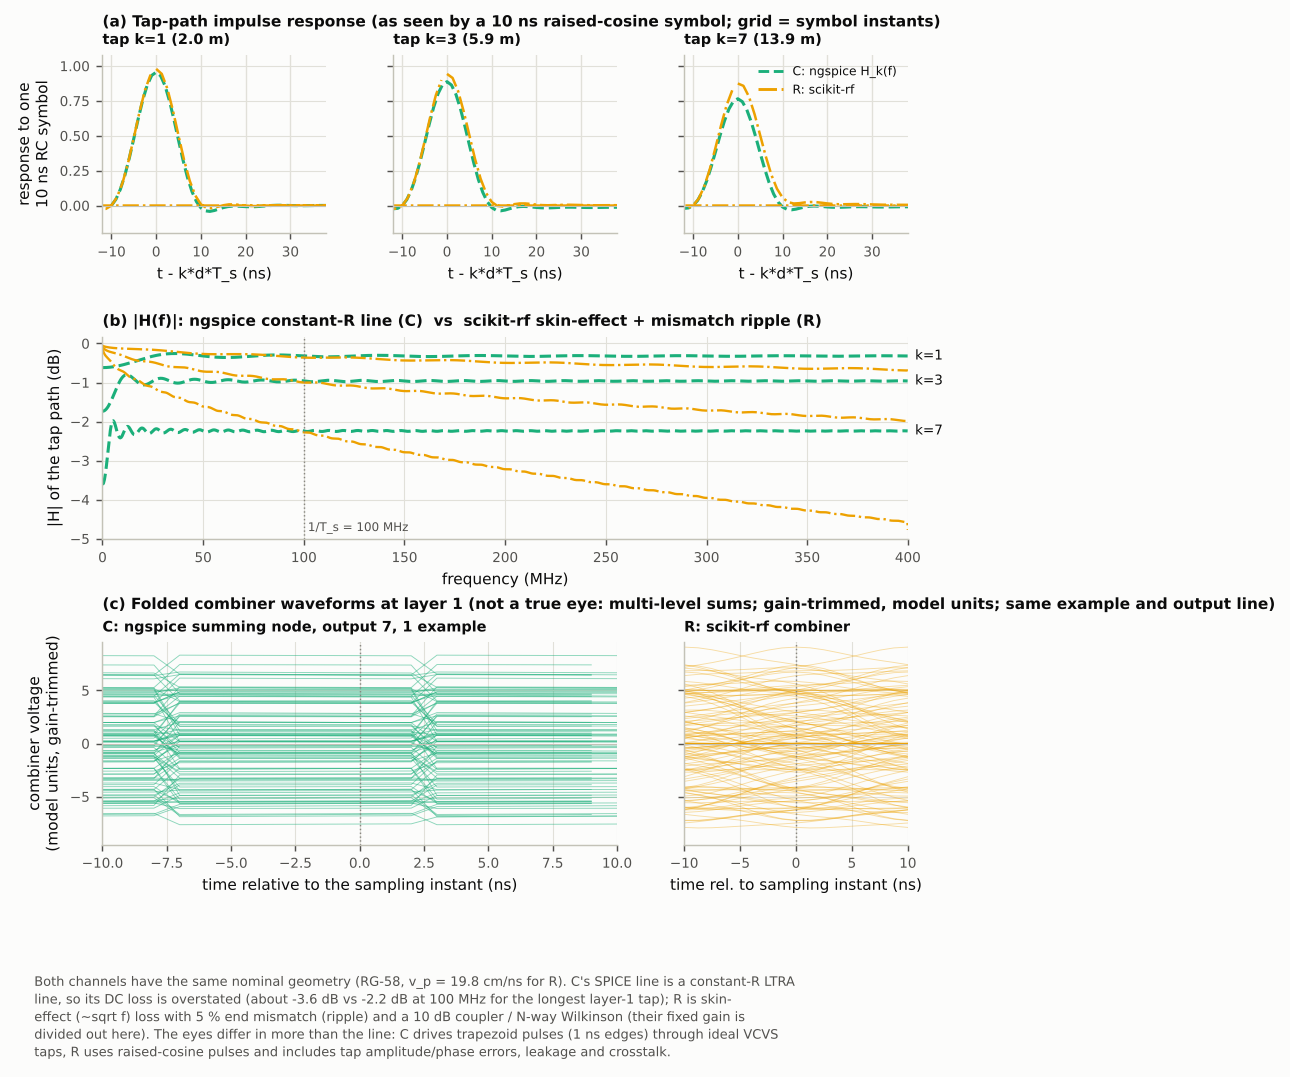

In [7]:
nb.show('fig3_channel', run)

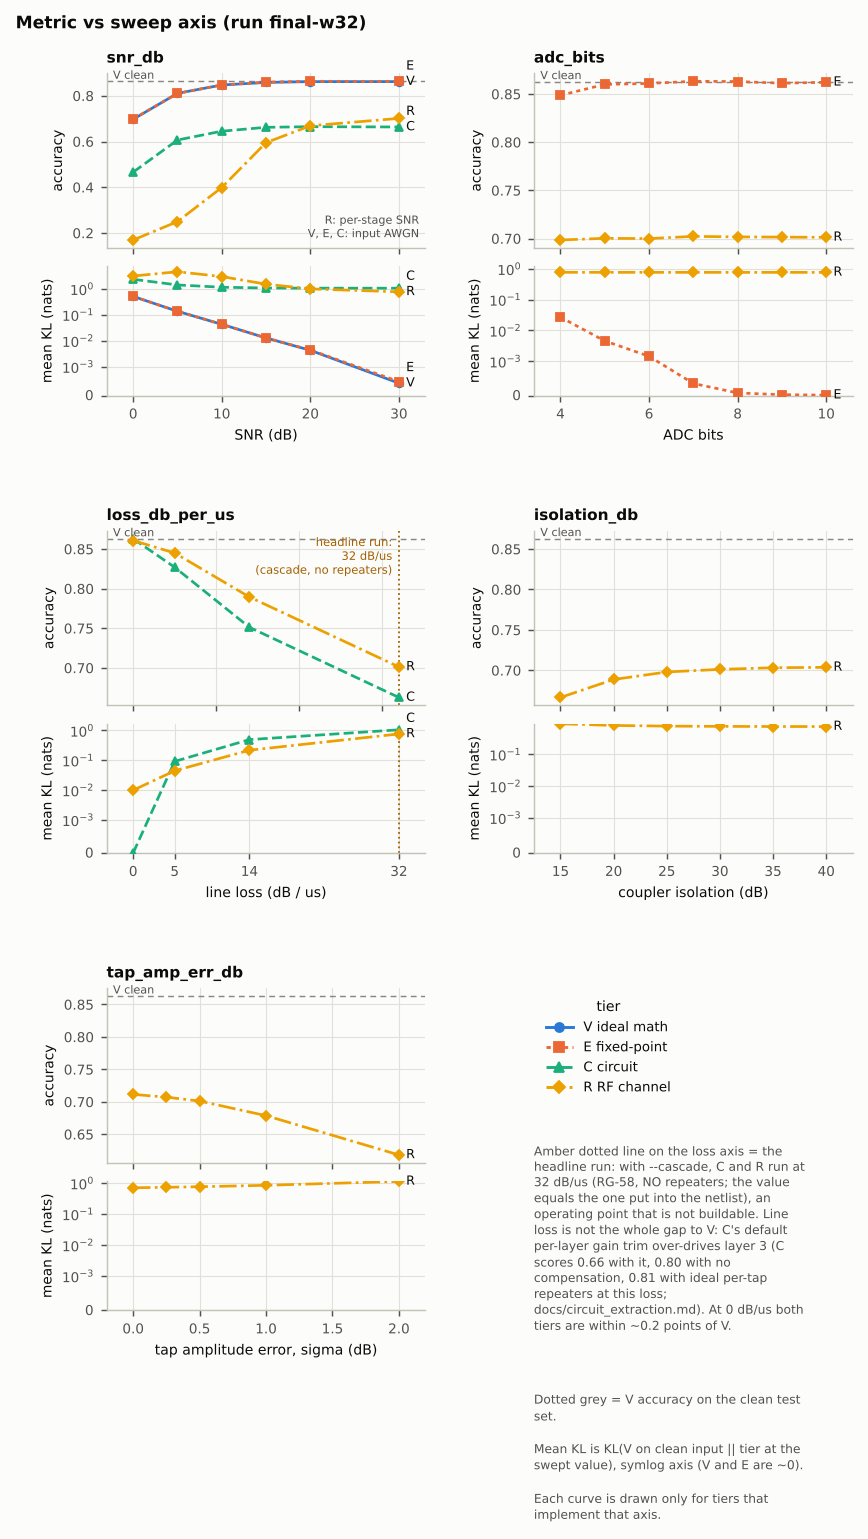

In [8]:
nb.show('fig5_sweeps', run)